In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!wget $data -O course_lead_scoring_2026.csv

--2026-10-19 09:29:43--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.02s   

2026-10-19 09:29:43 (11.3 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [ ]:
import pandas as pd
df = pd.read_csv('course_lead_scoring_2026.csv')

df.head().T

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


# Data preparation

In [6]:
# check the data types of the features
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [41]:
#classify the features into categorical and numerical
categorical_features = df.select_dtypes(include=['str', 'object', 'string']).columns
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

categorical_features, numerical_features

(Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str'),
 Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
        'lead_score', 'converted'],
       dtype='str'))

In [9]:
#Check if the missing values are presented in the features.
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [42]:
#If there are missing values:
#    For categorical features, replace them with 'NA'
#    For numerical features, replace with with 0.0

for c in categorical_features:
    df[c] = df[c].fillna('NA')

for c in numerical_features:
    df[c] = df[c].fillna(0.0)

#check if the missing values are replaced
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [44]:
#remove the target variable from the numerical features
numerical_features = numerical_features.drop('converted')
numerical_features

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='str')

In [ ]:
#Split the data into 3 parts with these exact calls
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


#Resetting the index
df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)



#extracting the target variable, deleting the target variable from the dataframe
y_full_train = df_full_train.pop('converted')
y_train = df_train.pop('converted')
y_val = df_val.pop('converted')
y_test = df_test.pop('converted')

# Question 1: ROC AUC feature importance

In [46]:
# For each numerical variable:
#   use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
#   use the training dataset for that
from sklearn.metrics import roc_auc_score


df_roc_auc_features = pd.DataFrame()

for c in numerical_features:
    c_roc_auc_score = roc_auc_score(y_train, df_train[c])
    c_roc_auc_max_score = max(c_roc_auc_score, 1 - c_roc_auc_score)
    df_c_row = pd.DataFrame({
        "feature": [c],
        "roc_auc_score": [c_roc_auc_score],
        "roc_auc_max_score": [c_roc_auc_max_score],
    })    
    df_roc_auc_features = pd.concat([df_roc_auc_features, df_c_row])

df_roc_auc_features.sort_values(by='roc_auc_max_score', ascending=False)

,feature,roc_auc_score,roc_auc_max_score
0,lead_score,0.788225,0.788225
0,interaction_count,0.764920,0.764920
0,number_of_courses_viewed,0.722989,0.722989
0,annual_income,0.608198,0.608198


# Question 2: Training the model

In [48]:
df_train.head().T

,0,1,2,3,4
lead_source,paid_ads,paid_ads,NA,paid_ads,organic_search
industry,technology,retail,finance,finance,finance
employment_status,employed,employed,employed,employed,employed
location,asia,asia,NA,NA,asia
annual_income,80198.0,50548.0,76300.0,80371.0,73567.0
number_of_courses_viewed,5,2,0,2,2
interaction_count,9,5,3,6,4
lead_score,0.91,0.48,0.42,0.49,0.48


In [49]:
categorical_features , numerical_features

(Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='str'),
 Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
        'lead_score'],
       dtype='str'))

In [52]:
#Apply one-hot-encoding using DictVectorizer
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical_features.append(numerical_features)].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

#see what columns the vectorizer created:
dv.get_feature_names_out()

array(['annual_income', 'employment_status=NA',
       'employment_status=employed', 'employment_status=self_employed',
       'employment_status=student', 'employment_status=unemployed',
       'industry=NA', 'industry=education', 'industry=finance',
       'industry=healthcare', 'industry=manufacturing', 'industry=retail',
       'industry=technology', 'interaction_count', 'lead_score',
       'lead_source=NA', 'lead_source=events',
       'lead_source=organic_search', 'lead_source=paid_ads',
       'lead_source=referral', 'lead_source=social_media', 'location=NA',
       'location=africa', 'location=asia', 'location=europe',
       'location=north_america', 'location=south_america',
       'number_of_courses_viewed'], dtype=object)

In [53]:
# train the logistic regression with these parameters:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [57]:
# apply model to the validation dataset
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)
y_pred = model.predict_proba(X_val)[:, 1]

In [58]:
#What's the AUC of this model on the validation dataset? (round to 3 digits)
from sklearn.metrics import roc_auc_score
roc_auc_score(y_val, y_pred)

0.7318222288173319

# Question 3: Precision and Recall

In [62]:
#compute precision and recall for our model.
#Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
#For each threshold, compute precision and recall

import numpy as np

def calculate_roc_scores(y_val, y_pred):
    scores = []

    thresholds = np.linspace(0, 1, 101)

    for t in thresholds:
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)
        
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        
        scores.append((t, tp, fp, fn, tn))

    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores




#Plot them
import matplotlib.pyplot as plt
def plot_roc_curve(df_scores):
    plt.plot(df_scores.threshold, df_scores['precision'], label='precision')
    plt.plot(df_scores.threshold, df_scores['recall'], label='recall')
    plt.xlabel('Threshold')
    plt.ylabel('Rate')
    plt.legend()

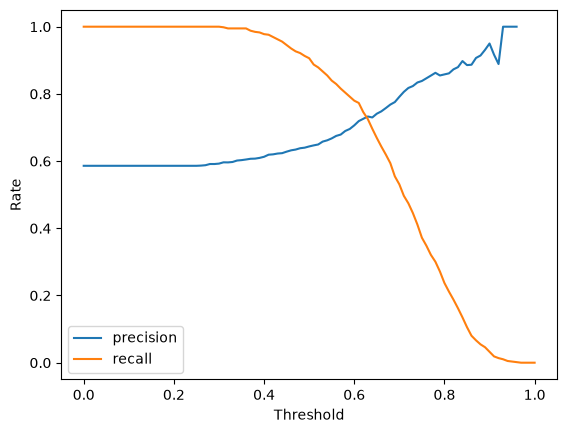

In [63]:
df_scores = calculate_roc_scores(y_val, y_pred)
plot_roc_curve(df_scores)

In [67]:
df_scores.iloc[(df_scores.precision - df_scores.recall).abs().argmin()].threshold

np.float64(0.63)

# Question 4: F1 score

In [68]:
#Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01
df_scores['f1'] = 2 * df_scores.precision * df_scores.recall / (df_scores.precision + df_scores.recall)

df_scores.head().T

,0,1,2,3,4
threshold,0.000000,0.010000,0.020000,0.030000,0.040000
tp,586.000000,586.000000,586.000000,586.000000,586.000000
fp,414.000000,414.000000,414.000000,414.000000,414.000000
fn,0.000000,0.000000,0.000000,0.000000,0.000000
tn,0.000000,0.000000,0.000000,0.000000,0.000000
precision,0.586000,0.586000,0.586000,0.586000,0.586000
recall,1.000000,1.000000,1.000000,1.000000,1.000000
tpr,1.000000,1.000000,1.000000,1.000000,1.000000
fpr,1.000000,1.000000,1.000000,1.000000,1.000000
f1,0.738966,0.738966,0.738966,0.738966,0.738966


In [69]:
#At which threshold F1 is maximal?
df_scores.iloc[(df_scores.f1).argmax()].threshold

np.float64(0.41000000000000003)

# Question 5: 5-Fold CV

In [89]:
#Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:
from sklearn.model_selection import KFold
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

In [91]:
from sklearn.feature_extraction import DictVectorizer

scores = []

# Iterate over different folds of df_full_train
for train_idx, val_idx in kfold.split(df_full_train):
    # Split the data into train and validation
    df_fold_train = df_full_train.iloc[train_idx]
    y_fold_train = y_full_train[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]
    y_fold_val = y_full_train[val_idx]

    # Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)    
    fold_train_dict = df_fold_train.to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    
    X_fold_train = dv.fit_transform(fold_train_dict)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_fold_train, y_fold_train)

    # Apply the model to the validation dataset
    fold_val_dicts = df_fold_val.to_dict(orient='records')
    X_fold_val = dv.transform(fold_val_dicts)
    y_pred = model.predict_proba(X_fold_val)[:, 1]
    
    # Use AUC to evaluate the model on validation
    auc = roc_auc_score(y_fold_val, y_pred)
    scores.append(auc)


scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [92]:
# standard deviation across folds
np.std(scores)

np.float64(0.006853233151022138)

# Question 6: Hyperparameter Tuning

In [ ]:
#Now let's use 5-Fold cross-validation to find the best parameter C

# Initialize KFold with the same parameters as previously
from sklearn.model_selection import KFold
n_splits = 5
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

from sklearn.feature_extraction import DictVectorizer

scores_by_regularization = []

# Iterate over the following C values: [0.000001, 0.001, 1]
from tqdm.auto import tqdm
for C in tqdm([0.000001, 0.001, 1]):
    
    for train_idx, val_idx in kfold.split(df_full_train):
        # Split the data into train and validation
        df_fold_train = df_full_train.iloc[train_idx]
        y_fold_train = y_full_train[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]
        y_fold_val = y_full_train[val_idx]

        # Train the model on train
        fold_train_dict = df_fold_train.to_dict(orient='records')
        dv = DictVectorizer(sparse=False)
        
        X_fold_train = dv.fit_transform(fold_train_dict)

        # Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        model.fit(X_fold_train, y_fold_train)

        # Apply the model to the validation dataset
        fold_val_dicts = df_fold_val.to_dict(orient='records')
        X_fold_val = dv.transform(fold_val_dicts)
        y_pred = model.predict_proba(X_fold_val)[:, 1]
        
        # Use AUC to evaluate the model on validation
        auc = roc_auc_score(y_fold_val, y_pred)
        scores_by_regularization.append([C, auc])


scores_by_regularization

  0%|          | 0/3 [00:00<?, ?it/s]

[[1e-06, 0.5941004654148612],
 [1e-06, 0.6402137243565715],
 [1e-06, 0.6001570384100505],
 [1e-06, 0.6364466933726896],
 [1e-06, 0.6127532038032245],
 [0.001, 0.7504349221633766],
 [0.001, 0.7475333388395098],
 [0.001, 0.7583539285346514],
 [0.001, 0.7584127166669861],
 [0.001, 0.7311259818106656],
 [1, 0.7305601027122453],
 [1, 0.7295726148196622],
 [1, 0.7363428071259397],
 [1, 0.7412454717957564],
 [1, 0.7209138590326581]]

In [100]:
# Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits)
df_scores_by_regularization_and_fold = pd.DataFrame(scores_by_regularization, columns=['C', 'auc'])
df_scores_by_regularization = df_scores_by_regularization_and_fold.groupby('C').auc.agg(['mean', 'std']).round(3)
df_scores_by_regularization.head()

,mean,std
C,,
0.000001,0.617,0.021
0.001000,0.749,0.011
1.000000,0.732,0.008
